In [1]:
# Zachary Katz
# zachary_katz@mines.edu
# 11 November 2026

"""
Programatically download n tracks of SWOT L3_LR_SSH_Expert data for all available
cycles, clean, and calculate tides in an harmonic inversion.
"""

# Imports
import altimetry_downloader_aviso
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import xarray as xr
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from utide import solve
import matplotlib.dates as mdates
from joblib import Parallel, delayed

output_dir = "./_Data/Test_four"
full_dir = "./_Data/Test_full"

In [1]:
# Download SWOT
# Still takes 2 mins even if everything already downloaded!
altimetry_downloader_aviso.get("SWOT_L3_LR_SSH_Expert", output_dir=output_dir, cycle_number=list(range(1,59)), pass_number=[201, 214, 479, 520])


NameError: name 'altimetry_downloader_aviso' is not defined

In [ ]:
# Skips chunks, may be better to download serially
passes = list(range(1,585)) # Swot has 584 passes
chunk_number = 6 
passes_per_chunk = len(passes) // chunk_number
chunks = [passes[i:i + passes_per_chunk] for i in range(0, len(passes), passes_per_chunk)]

def download_chunk(chunk):
    print(f"Downloading chunk: {chunk}")
    altimetry_downloader_aviso.get("SWOT_L3_LR_SSH_Expert", output_dir=full_dir, cycle_number=list(range(57,58)), pass_number=chunk)

with ThreadPoolExecutor(max_workers=(chunk_number + 1)) as executor:
    executor.map(download_chunk, chunks)

In [14]:
download_chunk(chunks[1]) # Download the last chunk

In [2]:
# Test SSH of cycle 57
data_paths = Path(full_dir).glob("SWOT_L3_LR_SSH_Expert_*.nc")
data_df = [xr.open_dataset(path) for path in data_paths]

In [7]:
bad = [i for i, df in enumerate(data_df)
       if np.ptp(((df['longitude'] + 180) % 360 - 180).values) > 180]
print(bad)

[0, 1, 2, 7, 9, 12, 16, 18, 20, 23, 24, 25, 29, 34, 37, 41, 53, 55, 56, 58, 61, 63, 64, 65, 70, 72, 73, 76, 77, 78, 81, 83, 84, 86, 89, 90, 91, 92, 97, 98, 102, 104, 109, 110, 112, 115, 116, 119, 122, 126, 127, 128, 129, 130, 133, 134, 136, 138, 147, 149, 155, 156, 159, 161, 166, 167, 169, 171, 173, 175, 176, 177, 178, 179, 180, 181, 182, 184, 185, 189, 192, 194, 195, 196, 197, 198, 200, 205, 210, 215, 216, 217, 221, 222, 223, 226, 229, 230, 233, 235, 237, 240, 241, 243, 244, 245, 249, 252, 256, 258, 262, 263, 266, 271, 272, 273, 274, 276, 277, 279, 280, 281, 282, 284, 285, 286, 287, 289, 292, 293, 294, 298, 300, 301, 304, 305, 307, 311, 312, 313, 315, 316, 318, 322, 323, 324, 325, 327, 328, 329, 330, 332, 333, 336, 337, 341, 342, 343, 344, 349, 352, 353, 355, 356, 368, 371, 372, 373, 375, 376, 378, 379, 382, 386, 388, 393, 394, 395, 398, 402, 403, 405, 406, 407, 409, 410, 411, 412, 415, 416, 417, 418, 419, 421, 422, 423, 424, 428, 429, 432, 434, 438, 439, 440, 442, 444, 445, 451, 453,

ValueError: x and y arguments to pcolormesh cannot have non-finite values or be of type numpy.ma.MaskedArray with masked values

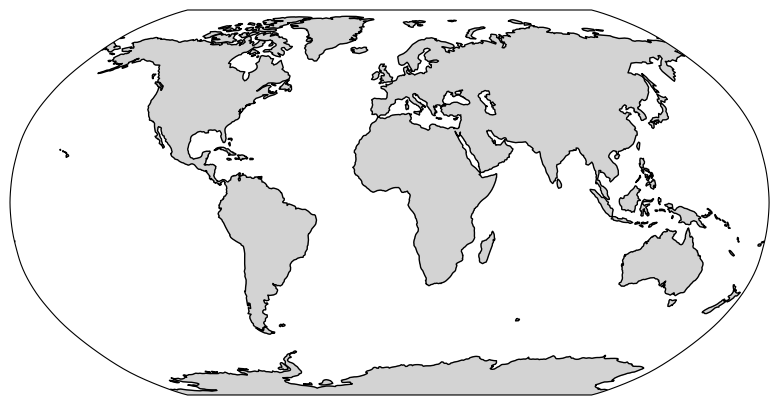

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5),subplot_kw={'projection': ccrs.Robinson()})
# Add grey continents using cfeature
for df in data_df[::5]:
    cb = ax.pcolormesh(df['longitude'], df['latitude'], df['ssha_filtered'], shading='auto',transform=ccrs.PlateCarree(), cmap='seismic', alpha=1, vmin=-1, vmax=1)
# Add coastlines
ax.set_facecolor('white')
ax.add_feature(
    cfeature.LAND,
    facecolor='lightgray',
    edgecolor='gray',
    linewidth=0.3,
    zorder=0
)
ax.coastlines()
#ax.set_extent([-5, 0, 60, 65], crs=ccrs.PlateCarree())
ax.set_extent([-180, 180, -90, 90], crs=ccrs.PlateCarree())
# Add colorbar
cbar = plt.colorbar(cb, ax=ax, orientation='horizontal', pad=0.05,extend='both', label='SSH Anomaly [m]')

In [2]:
# Load and inspect data
# Plot 1st cycle on map

data_paths = Path(output_dir).glob("SWOT_L3_LR_SSH_Expert*_214_*.nc")
data_df = [xr.open_dataset(path) for path in data_paths]

In [3]:
lines = []
pixels = []
for df in data_df:
    num_lines = df.sizes['num_lines']
    num_pixels = df.sizes['num_pixels']
    lines.append(num_lines)
    pixels.append(num_pixels)

# Assert all elements of lines and pixels are the same
assert all(x == lines[0] for x in lines), "Not all elements of lines are the same"
assert all(x == pixels[0] for x in pixels), "Not all elements of pixels are the same"

In [ ]:
dfs_no_nadir = []
# Drop conflicting num_nadir dimenstion and i_num_line, i_num_pixel vals which depend on it
for df in data_df:
    try:
        df_dropped = df.drop_vars(['i_num_line', 'i_num_pixel'])
    except ValueError:
        print(df)
    dfs_no_nadir.append(df_dropped)

<xarray.Dataset> Size: 99MB
Dimensions:               (num_lines: 9860, num_pixels: 69)
Coordinates:
    latitude              (num_lines, num_pixels) float64 5MB ...
    longitude             (num_lines, num_pixels) float64 5MB ...
Dimensions without coordinates: num_lines, num_pixels
Data variables: (12/19)
    time                  (num_lines) datetime64[ns] 79kB ...
    calibration           (num_lines, num_pixels) float64 5MB ...
    cross_track_distance  (num_pixels) float64 552B ...
    dac                   (num_lines, num_pixels) float64 5MB ...
    internal_tide         (num_lines, num_pixels) float64 5MB ...
    mdt                   (num_lines, num_pixels) float64 5MB ...
    ...                    ...
    ugos_filtered         (num_lines, num_pixels) float64 5MB ...
    ugosa_filtered        (num_lines, num_pixels) float64 5MB ...
    ugosa_unfiltered      (num_lines, num_pixels) float64 5MB ...
    vgos_filtered         (num_lines, num_pixels) float64 5MB ...
    vgosa_fi

In [5]:
# Stack all dataframes into one
data_df = xr.concat(dfs_no_nadir, dim='cycle_number')
data_df["ssha_detided"] = data_df["ssha_filtered"] + data_df["ocean_tide"]

: 

In [4]:
lines = slice(1294, 8335)      # the usable range from earlier; or a single row: slice(2163, 2164)
keep = ["time", "ssha_filtered", "ocean_tide", "latitude", "longitude"]

small = []
for ds in dfs_no_nadir:
    d = ds[keep].isel(num_lines=lines)
    d["ssha_detided"] = (d["ssha_filtered"] + d["ocean_tide"]).astype("float32")
    d = d.drop_vars(["ssha_filtered", "ocean_tide"])
    small.append(d.load())      # load only the subset, then release the file

lat = small[0]["latitude"].values
lon = small[0]["longitude"].values

data_df = xr.concat(
    [d[["time", "ssha_detided"]] for d in small],
    dim="cycle_number",
)
data_df = data_df.assign_coords(
    latitude=(("num_lines", "num_pixels"), lat),
    longitude=(("num_lines", "num_pixels"), lon),
)
del small

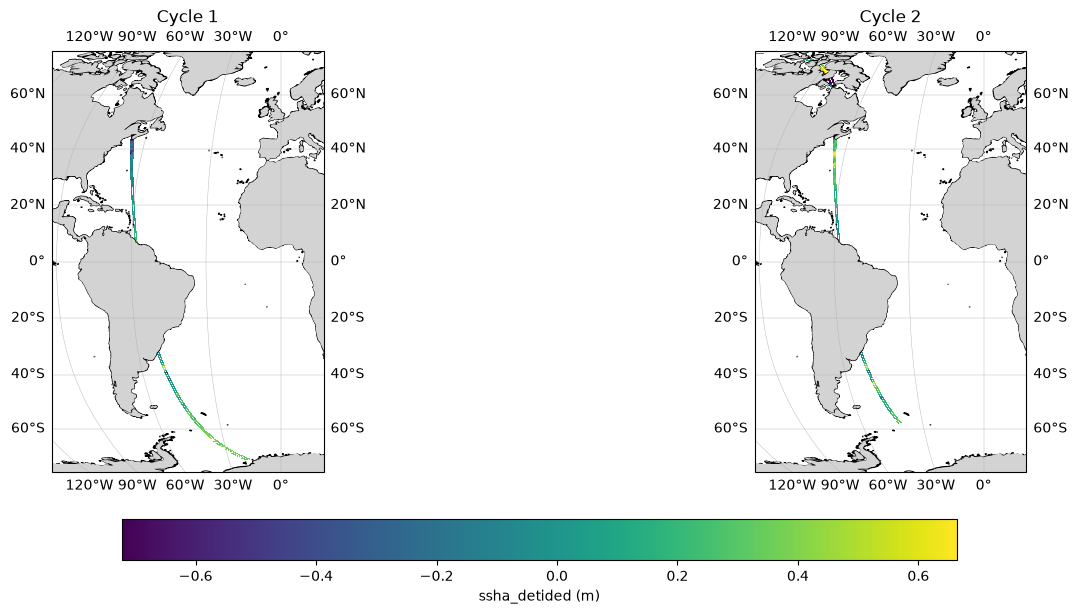

In [55]:
# Example plot of a few cycles 
cycles = [1,2]
vmin, vmax = data_df["ssha_detided"].sel(cycle_number=cycles).quantile([0.02, 0.98]).values

fig, axes = plt.subplots(
    1, 2, figsize=(14, 6),
    subplot_kw={"projection": ccrs.Robinson()},
    constrained_layout=True,
)

for ax, c in zip(axes, cycles):
    d = data_df.sel(cycle_number=c)
    lon = d["longitude"]
    lon = ((lon + 180) % 360) - 180      # wrap to -180..180 to avoid streaks
    m = ax.pcolormesh(
        lon, d["latitude"], d["ssha_detided"],
        shading="auto", transform=ccrs.PlateCarree(),
        cmap="viridis", vmin=vmin, vmax=vmax,
    )
    ax.coastlines(resolution="50m")
    ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=2)
    ax.gridlines(draw_labels=True, linewidth=0.3)
    ax.set_title(f"Cycle {int(c)}")

fig.colorbar(m, ax=axes, orientation="horizontal", shrink=0.6, pad=0.05,
             label="ssha_detided (m)")
plt.show()

In [5]:
import time
constits = ["M2", "S2", "N2", "K2", "K1", "O1", "P1", "Q1"]
min_obs = 40

# ---- inputs (data_df = concatenated dataset with 'time' and 'ssha_detided') ----
tv = data_df["time"].values                                   # (cycle, num_lines)
tnum = tv.astype("datetime64[ns]").astype(np.int64) / 86400e9 + 719163   # python ordinal days
tnum[np.isnat(tv)] = np.nan

h = data_df["ssha_detided"].values.astype("float32")          # (cycle, num_lines, num_pixels)
lat = np.asarray(data_df["latitude"].values)                  # (num_lines, num_pixels)
lon = np.asarray(data_df["longitude"].values)

nvalid = np.isfinite(h).sum(axis=0)
lines = np.where((nvalid >= min_obs).any(axis=1))[0]          # positions along num_lines
print("lines to fit:", lines.size, "| points:", int((nvalid >= min_obs).sum()))

# ---- fitting ----
def fit_line(t_j, h_j, lat_j):
    """t_j: (cycle,), h_j: (cycle, num_pixels), lat_j: (num_pixels,)"""
    npx = h_j.shape[1]
    amp = np.full((len(constits), npx), np.nan, dtype="float32")
    pha = np.full((len(constits), npx), np.nan, dtype="float32")
    for i in range(npx):
        y = h_j[:, i].astype("float64")
        ok = np.isfinite(y) & np.isfinite(t_j)
        if ok.sum() < min_obs or not np.isfinite(lat_j[i]):
            continue
        try:
            c = solve(t_j[ok], y[ok], lat=float(lat_j[i]), constit=constits,
                      epoch="python", nodal=False, phase="Greenwich",
                      trend=False, method="ols", conf_int="none", verbose=False)
        except Exception:
            continue
        names = list(c.name)
        for k, name in enumerate(constits):
            if name in names:
                idx = names.index(name)
                amp[k, i], pha[k, i] = c.A[idx], c.g[idx]
    return amp, pha

# ---- time one line to estimate the full run ----
t0 = time.time()
j0 = lines[0]
r = fit_line(tnum[:, j0], h[:, j0, :], lat[j0])
dt = time.time() - t0
print(f"{dt:.1f} s/line -> ~{dt * lines.size / 60:.0f} min serial; finite amps in test: {int(np.isfinite(r[0]).sum())}")

lines to fit: 3893 | points: 196758
0.0 s/line -> ~0 min serial; finite amps in test: 8


In [6]:
res = Parallel(n_jobs=3, batch_size=10, verbose=5)(
    delayed(fit_line)(tnum[:, j], h[:, j, :], lat[j]) for j in lines
)
print(len(res))  

amp = np.stack([r[0] for r in res], axis=1)    # (constituent, n_lines, num_pixels)
pha = np.stack([r[1] for r in res], axis=1)

tide_fit = xr.Dataset(
    {"amplitude": (("constituent", "num_lines", "num_pixels"), amp),
     "phase": (("constituent", "num_lines", "num_pixels"), pha)},
    coords={"constituent": constits,
            "num_lines": lines,
            "latitude": (("num_lines", "num_pixels"), lat[lines]),
            "longitude": (("num_lines", "num_pixels"), lon[lines])},
)
tide_fit["amplitude"].attrs["units"] = "m"
tide_fit["phase"].attrs["units"] = "degrees (Greenwich)"

tide_fit.to_netcdf("swot_tide_fit.nc") 

[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.
[Parallel(n_jobs=3)]: Done 126 tasks      | elapsed:    3.5s
[Parallel(n_jobs=3)]: Done 666 tasks      | elapsed:   24.1s
[Parallel(n_jobs=3)]: Done 1566 tasks      | elapsed:  1.0min
[Parallel(n_jobs=3)]: Done 2826 tasks      | elapsed:  1.8min


KeyboardInterrupt: 

1574064 finite values


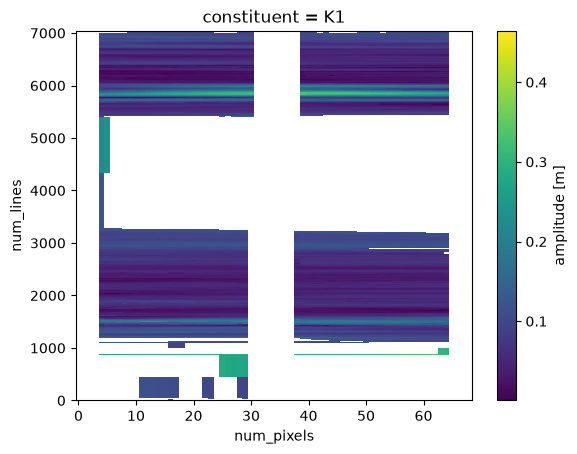

In [7]:
tide_fit = xr.open_dataset("swot_tide_fit.nc")
print(int(np.isfinite(tide_fit["amplitude"]).sum()), "finite values")
tide_fit["amplitude"].sel(constituent="K1").plot(x="num_pixels", y="num_lines")

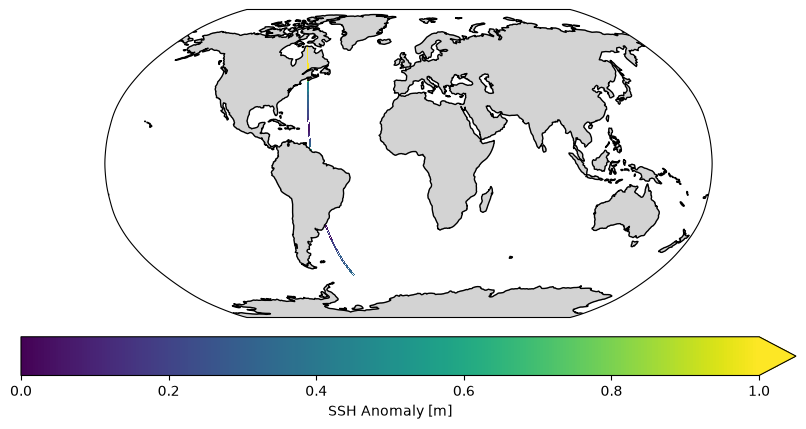

In [8]:
fig, ax = plt.subplots(figsize=(10, 5),subplot_kw={'projection': ccrs.Robinson()})
# Add grey continents using cfeature
cb = ax.pcolormesh(tide_fit["longitude"], tide_fit["latitude"], tide_fit["amplitude"].sel(constituent="M2"), shading='auto',transform=ccrs.PlateCarree(), cmap='viridis', alpha=1, vmin=0, vmax=1)
# Add coastlines
ax.set_facecolor('white')
ax.add_feature(
    cfeature.LAND,
    facecolor='lightgray',
    edgecolor='gray',
    linewidth=0.3,
    zorder=0
)
ax.coastlines()
#ax.set_extent([-5, 0, 60, 65], crs=ccrs.PlateCarree())
ax.set_extent([-180, 180, -90, 90], crs=ccrs.PlateCarree())
# Add colorbar
cbar = plt.colorbar(cb, ax=ax, orientation='horizontal', pad=0.05,extend='max', label='SSH Anomaly [m]')

In [26]:
import pyTMD
model_dir = "/mnt/c/Users/ZacharyKatz/Desktop/Research/Background/GOT5.6"    
model_name = "GOT5.6"
m = pyTMD.io.model(model_dir).from_database(model_name)
print(m)      

pyTMD.io.model
    name: GOT5.6


In [31]:
# Load GOT5.6 and compare at the same lats/lons
amp_s = tide_fit["amplitude"].values          # (const, lines, pixels)
pha_s = tide_fit["phase"].values
lat_s = tide_fit["latitude"].values           # (lines, pixels)
lon_s = tide_fit["longitude"].values

valid = np.isfinite(amp_s).all(axis=0)
jj, ii = np.where(valid)
lon_p, lat_p = lon_s[jj, ii], lat_s[jj, ii]
names = [c.lower() for c in constits]

In [30]:
m = pyTMD.io.model(model_dir).from_database("GOT5.6")   # load once, not on every call
ds = m.open_dataset(group="z")

def got_constants(lon, lat, names, batch=20000):
    """Pointwise interpolation. Returns amp (m) and Greenwich phase (deg), shape (n_const, n_points)."""
    n = lon.size
    amp = np.full((len(names), n), np.nan)
    ph = np.full((len(names), n), np.nan)
    for s in range(0, n, batch):
        sl = slice(s, min(s + batch, n))
        x = xr.DataArray(lon[sl], dims="points")
        y = xr.DataArray(lat[sl], dims="points")
        local = ds.tmd.interp(x, y, extrapolate=True)
        hc = np.stack([np.asarray(local[c].values) for c in names])
        assert hc.shape == (len(names), sl.stop - sl.start), hc.shape   # catches the grid case early
        amp[:, sl] = np.abs(hc)
        ph[:, sl] = np.degrees(np.arctan2(-hc.imag, hc.real)) % 360
    return amp, ph

# test on a small slice first
amp_f, pha_f = got_constants(lon_p[:], lat_p[:], names)

In [32]:
A_s = amp_s[:, jj, ii]
P_s = pha_s[:, jj, ii]

dA = A_s - amp_f
dP = (P_s - pha_f + 180) % 360 - 180                   
vec = np.sqrt(A_s**2 + amp_f**2 - 2*A_s*amp_f*np.cos(np.radians(P_s - pha_f)))

# Vector diff in amp and phase
for k, c in enumerate(constits):
    print(f"{c}: median |dA| = {np.nanmedian(np.abs(dA[k]))*100:5.1f} cm | "
          f"median |dphase| = {np.nanmedian(np.abs(dP[k])):5.1f}° | "
          f"RMS vector diff = {np.sqrt(np.nanmean(vec[k]**2))*100:5.1f} cm")

M2: median |dA| =   2.5 cm | median |dphase| =   2.9° | RMS vector diff =   4.8 cm
S2: median |dA| =   1.0 cm | median |dphase| =  14.5° | RMS vector diff =   3.7 cm
N2: median |dA| =   0.9 cm | median |dphase| =   9.5° | RMS vector diff =   3.2 cm
K2: median |dA| =   1.4 cm | median |dphase| =  31.3° | RMS vector diff =   3.8 cm
K1: median |dA| =   1.8 cm | median |dphase| =  19.9° | RMS vector diff =   7.3 cm
O1: median |dA| =   1.0 cm | median |dphase| =   7.7° | RMS vector diff =   3.5 cm
P1: median |dA| =   1.2 cm | median |dphase| =  42.3° | RMS vector diff =   4.0 cm
Q1: median |dA| =   1.1 cm | median |dphase| =  23.7° | RMS vector diff =   3.0 cm


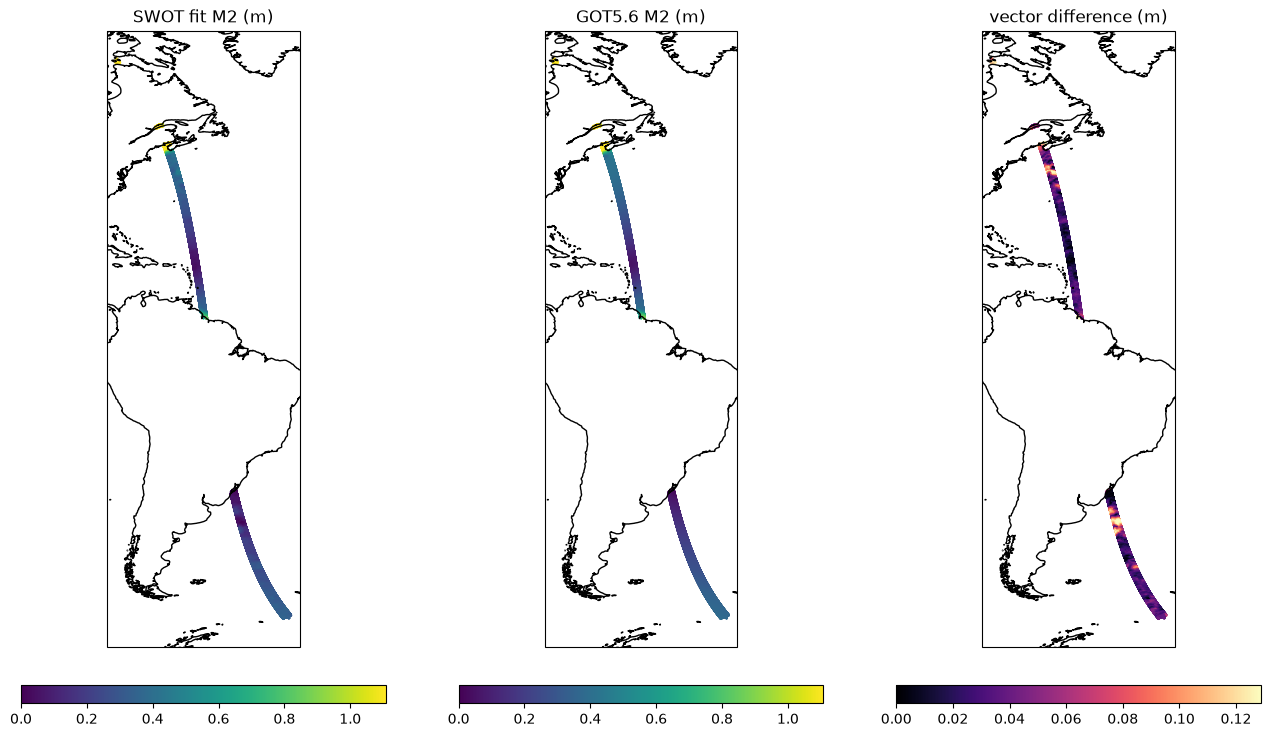

In [35]:
k = constits.index("M2")
fig, axs = plt.subplots(1, 3, figsize=(16, 10), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, v, ttl, cm, lim in zip(
        axs, [A_s[k], amp_f[k], vec[k]],
        ["SWOT fit M2 (m)", "GOT5.6 M2 (m)", "vector difference (m)"],
        ["viridis", "viridis", "magma"],
        [(0, np.nanpercentile(amp_f[k], 98))]*2 + [(0, np.nanpercentile(vec[k], 98))]):
    sc = ax.scatter(lon_p, lat_p, c=v, s=1, cmap=cm, vmin=lim[0], vmax=lim[1], transform=ccrs.PlateCarree())
    ax.coastlines(); ax.set_title(ttl); plt.colorbar(sc, ax=ax, orientation="horizontal", pad=0.05)
plt.show()

In [1]:
# RERUN AS LOOP OVER SWOT PASSES AND SAVE NETCDF OF TIDE FITS and GOT5.6 Comparison Values

# Zachary Katz
# zachary_katz@mines.edu
# 17 November 2026

"""
Programatically download n tracks of SWOT L3_LR_SSH_Expert data for all available
cycles, clean, and calculate tides in an harmonic inversion.
"""

# Imports
import altimetry_downloader_aviso
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import xarray as xr
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from utide import solve
import matplotlib.dates as mdates
from joblib import Parallel, delayed
import time
import pyTMD

output_dir = "./_Data/Test_four"
line_slice = slice(1294, 5335)      # Pick a subset for this small test
keep = ["time", "ssha_filtered", "ocean_tide", "latitude", "longitude"]
constits = ["M2", "S2", "N2", "K2", "K1", "O1", "P1", "Q1"]
min_obs = 40 # 8 amp + 8 ph + 1 trend

model_dir = "/mnt/c/Users/ZacharyKatz/Desktop/Research/Background/GOT5.6"    
model_name = "GOT5.6"
m = pyTMD.io.model(model_dir).from_database(model_name)   
ds_got = m.open_dataset(group="z")

# Load and inspect data
for swot_pass in [201, 214, 479, 520]:
    data_paths = Path(output_dir).glob(f"SWOT_L3_LR_SSH_Expert*_{swot_pass}_*.nc")
    data_df = [xr.open_dataset(path) for path in data_paths]

    print(f"Pass {swot_pass}: {len(data_df)} files loaded")

    dfs_no_nadir = []
    # Drop conflicting num_nadir dimenstion and i_num_line, i_num_pixel vals which depend on it
    for df in data_df:
        try:
            df_dropped = df.drop_vars(['i_num_line', 'i_num_pixel'])
        except ValueError:
            print(df)
        dfs_no_nadir.append(df_dropped)

    small = []
    for ds in dfs_no_nadir:
        d = ds[keep].isel(num_lines=line_slice)
        d["ssha_detided"] = (d["ssha_filtered"] + d["ocean_tide"]).astype("float32")
        d = d.drop_vars(["ssha_filtered", "ocean_tide"])
        small.append(d.load())      # load only the subset, then release the file

    lat = small[0]["latitude"].values
    lon = small[0]["longitude"].values

    data_df = xr.concat(
        [d[["time", "ssha_detided"]] for d in small],
        dim="cycle_number",
    )
    data_df = data_df.assign_coords(
        latitude=(("num_lines", "num_pixels"), lat),
        longitude=(("num_lines", "num_pixels"), lon),
    )
    del small

    # Fit tides for this pass
    print(f"Fitting tides for pass {swot_pass}")
    tv = data_df["time"].values                                   # (cycle, num_lines)
    tnum = tv.astype("datetime64[ns]").astype(np.int64) / 86400e9 + 719163   # python ordinal days
    tnum[np.isnat(tv)] = np.nan

    h = data_df["ssha_detided"].values.astype("float32")          # (cycle, num_lines, num_pixels)
    lat = np.asarray(data_df["latitude"].values)                  # (num_lines, num_pixels)
    lon = np.asarray(data_df["longitude"].values)

    nvalid = np.isfinite(h).sum(axis=0)
    fit_lines = np.where((nvalid >= min_obs).any(axis=1))[0]          # positions along num_lines
    print("lines to fit:", fit_lines.size, "| points:", int((nvalid >= min_obs).sum()))

    def fit_line(t_j, h_j, lat_j):
        """t_j: (cycle,), h_j: (cycle, num_pixels), lat_j: (num_pixels,)"""
        npx = h_j.shape[1]
        amp = np.full((len(constits), npx), np.nan, dtype="float32")
        pha = np.full((len(constits), npx), np.nan, dtype="float32")
        for i in range(npx):
            y = h_j[:, i].astype("float64")
            ok = np.isfinite(y) & np.isfinite(t_j)
            if ok.sum() < min_obs or not np.isfinite(lat_j[i]):
                continue
            try:
                c = solve(t_j[ok], y[ok], lat=float(lat_j[i]), constit=constits,
                        epoch="python", nodal=False, phase="Greenwich",
                        trend=False, method="ols", conf_int="none", verbose=False)
            except Exception:
                continue
            names = list(c.name)
            for k, name in enumerate(constits):
                if name in names:
                    idx = names.index(name)
                    amp[k, i], pha[k, i] = c.A[idx], c.g[idx]
        return amp, pha

    res = Parallel(n_jobs=3, batch_size=10, verbose=5)(
        delayed(fit_line)(tnum[:, j], h[:, j, :], lat[j]) for j in fit_lines
    )
    print(len(res))  

    amp = np.stack([r[0] for r in res], axis=1)    # (constituent, n_lines, num_pixels)
    pha = np.stack([r[1] for r in res], axis=1)

    tide_fit = xr.Dataset(
        {"amplitude": (("constituent", "num_lines", "num_pixels"), amp),
        "phase": (("constituent", "num_lines", "num_pixels"), pha)},
        coords={"constituent": constits,
                "num_lines": fit_lines,
                "latitude": (("num_lines", "num_pixels"), lat[fit_lines]),
                "longitude": (("num_lines", "num_pixels"), lon[fit_lines])},
    )
    tide_fit["amplitude"].attrs["units"] = "m"
    tide_fit["phase"].attrs["units"] = "degrees (Greenwich)"

    # Compare to GOT5.6
    amp_s = tide_fit["amplitude"].values          # (const, lines, pixels)
    pha_s = tide_fit["phase"].values
    lat_s = tide_fit["latitude"].values           # (lines, pixels)
    lon_s = tide_fit["longitude"].values

    valid = np.isfinite(amp_s).all(axis=0)
    jj, ii = np.where(valid)
    lon_p, lat_p = lon_s[jj, ii], lat_s[jj, ii]
    names = [c.lower() for c in constits]

    def got_constants(lon, lat, names, batch=20000):
        """Pointwise interpolation. Returns amp (m) and Greenwich phase (deg), shape (n_const, n_points)."""
        n = lon.size
        amp = np.full((len(names), n), np.nan)
        ph = np.full((len(names), n), np.nan)
        for s in range(0, n, batch):
            sl = slice(s, min(s + batch, n))
            x = xr.DataArray(lon[sl], dims="points")
            y = xr.DataArray(lat[sl], dims="points")
            local = ds_got.tmd.interp(x, y, extrapolate=True)
            hc = np.stack([np.asarray(local[c].values) for c in names])
            assert hc.shape == (len(names), sl.stop - sl.start), hc.shape
            amp[:, sl] = np.abs(hc)
            ph[:, sl] = np.degrees(np.arctan2(-hc.imag, hc.real)) % 360
        return amp, ph

    amp_f, pha_f = got_constants(lon_p[:], lat_p[:], names)

    A_s = amp_s[:, jj, ii]
    P_s = pha_s[:, jj, ii]

    dA = A_s - amp_f
    dP = (P_s - pha_f + 180) % 360 - 180                   
    vec = np.sqrt(A_s**2 + amp_f**2 - 2*A_s*amp_f*np.cos(np.radians(P_s - pha_f)))

    shape = amp_s.shape

    for name, values in {
        "amp_got": amp_f,
        "pha_got": pha_f,
        "dA": dA,
        "dP": dP,
        "vec": vec,
    }.items():
        out = np.full(shape, np.nan, dtype=np.float32)
        out[:, jj, ii] = values
        tide_fit[name] = (
            ("constituent", "num_lines", "num_pixels"),
            out
        )

    # Save to netcdf
    tide_fit.to_netcdf(f"swot_tide_fit_pass_{swot_pass}.nc")


Pass 201: 58 files loaded
Fitting tides for pass 201
lines to fit: 2676 | points: 140841


[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.
[Parallel(n_jobs=3)]: Done 126 tasks      | elapsed:    5.9s
[Parallel(n_jobs=3)]: Done 666 tasks      | elapsed:   26.3s
[Parallel(n_jobs=3)]: Done 1566 tasks      | elapsed:  1.0min
[Parallel(n_jobs=3)]: Done 2676 out of 2676 | elapsed:  1.7min finished


2676
Pass 214: 57 files loaded
<xarray.Dataset> Size: 99MB
Dimensions:               (num_lines: 9860, num_pixels: 69)
Coordinates:
    latitude              (num_lines, num_pixels) float64 5MB ...
    longitude             (num_lines, num_pixels) float64 5MB ...
Dimensions without coordinates: num_lines, num_pixels
Data variables: (12/19)
    time                  (num_lines) datetime64[ns] 79kB ...
    calibration           (num_lines, num_pixels) float64 5MB ...
    cross_track_distance  (num_pixels) float64 552B ...
    dac                   (num_lines, num_pixels) float64 5MB ...
    internal_tide         (num_lines, num_pixels) float64 5MB ...
    mdt                   (num_lines, num_pixels) float64 5MB ...
    ...                    ...
    ugos_filtered         (num_lines, num_pixels) float64 5MB ...
    ugosa_filtered        (num_lines, num_pixels) float64 5MB ...
    ugosa_unfiltered      (num_lines, num_pixels) float64 5MB ...
    vgos_filtered         (num_lines, num_pixel

[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.
[Parallel(n_jobs=3)]: Done 126 tasks      | elapsed:    2.9s
[Parallel(n_jobs=3)]: Done 666 tasks      | elapsed:   22.9s
[Parallel(n_jobs=3)]: Done 1566 tasks      | elapsed:   56.9s
[Parallel(n_jobs=3)]: Done 2247 out of 2247 | elapsed:  1.3min finished


2247
Pass 479: 57 files loaded
Fitting tides for pass 479
lines to fit: 2624 | points: 136693


[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.
[Parallel(n_jobs=3)]: Done 126 tasks      | elapsed:    4.9s
[Parallel(n_jobs=3)]: Done 666 tasks      | elapsed:   25.5s
[Parallel(n_jobs=3)]: Done 1566 tasks      | elapsed:   59.8s
[Parallel(n_jobs=3)]: Done 2624 out of 2624 | elapsed:  1.6min finished


2624
Pass 520: 56 files loaded
Fitting tides for pass 520
lines to fit: 2109 | points: 107027


[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.
[Parallel(n_jobs=3)]: Done 126 tasks      | elapsed:    4.0s
[Parallel(n_jobs=3)]: Done 666 tasks      | elapsed:   24.5s
[Parallel(n_jobs=3)]: Done 1566 tasks      | elapsed:   60.0s
[Parallel(n_jobs=3)]: Done 2109 out of 2109 | elapsed:  1.3min finished


2109


Plotting swot_tide_fit_pass_201.nc
Plotting swot_tide_fit_pass_214.nc
Plotting swot_tide_fit_pass_479.nc
Plotting swot_tide_fit_pass_520.nc


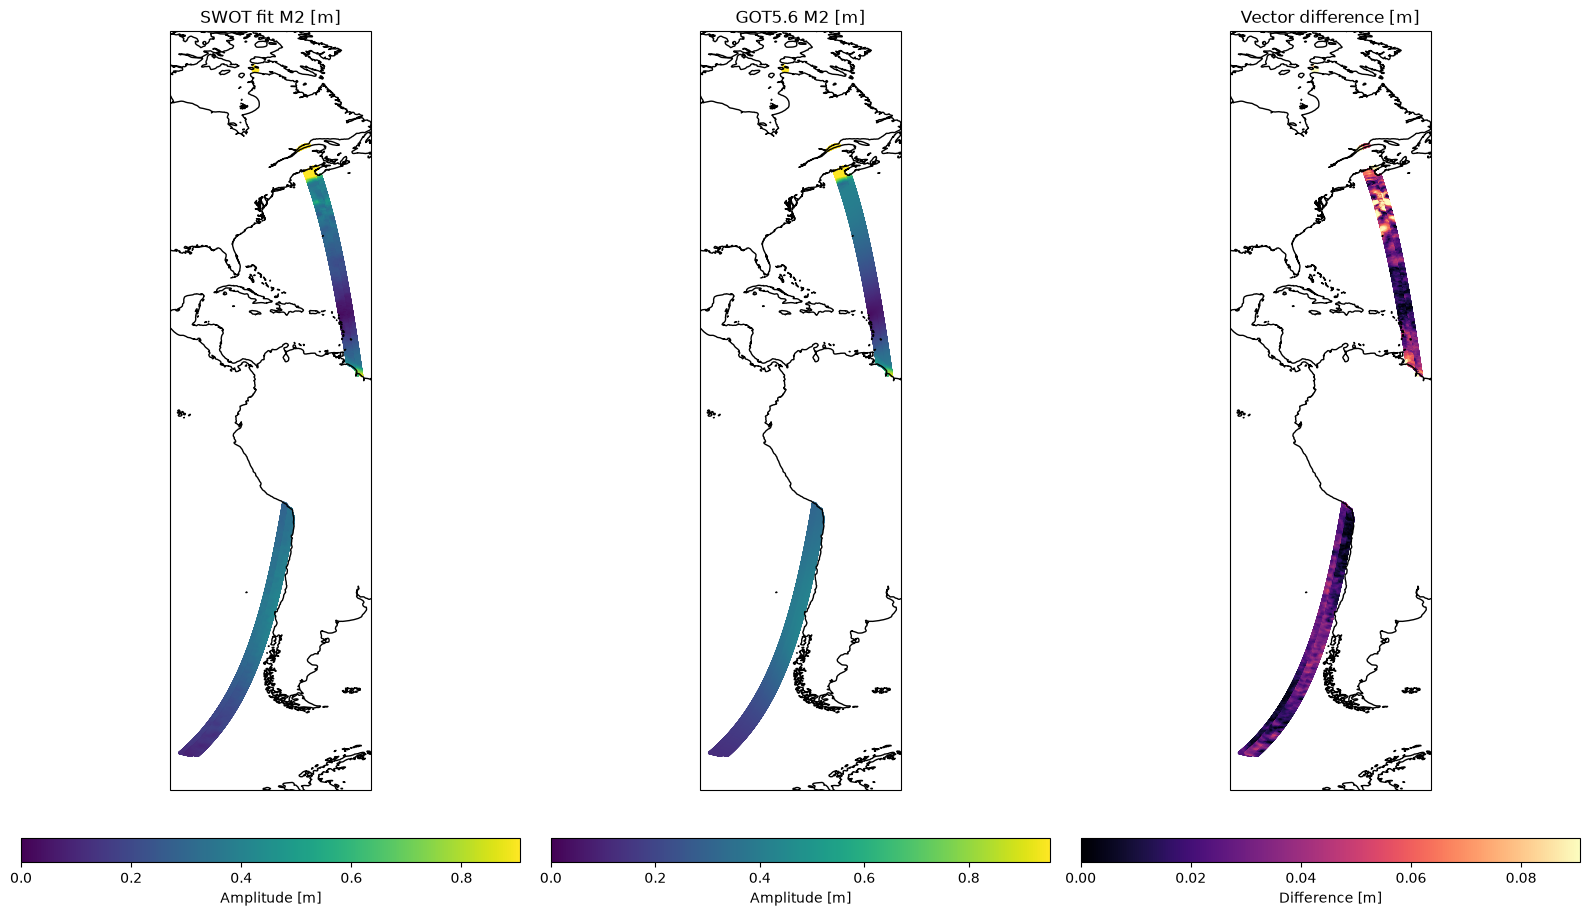

In [ ]:
for constituent in constits:
    k = constits.index(constituent)
    files = sorted(Path(".").glob("swot_tide_fit_pass_*.nc"))
    percentiles = [[] for _ in range(3)]
    # Calculate 98th percentile for each variable across all passes
    for path in files:
        with xr.open_dataset(path) as ds:
            for i, var in enumerate(["amplitude", "amp_got", "vec"]):
                v = ds[var].isel(constituent=k).values
                percentiles[i].append(v[np.isfinite(v)])
    limits = [(0, np.nanpercentile(np.concatenate(v), 98)) for v in percentiles]

    fig, axs = plt.subplots(1, 3, figsize=(16, 10), subplot_kw={"projection": ccrs.PlateCarree()})
    titles = ["SWOT fit M2 [m]","GOT5.6 M2 [m]","Vector difference [m]"]
    cmaps = ["viridis", "viridis", "magma"]

    for path in files:
        print(f"Plotting {path.name}")
        with xr.open_dataset(path) as ds:
            lon = ds["longitude"].values
            lat = ds["latitude"].values
            valid = (
                np.isfinite(ds["amplitude"].isel(constituent=k).values)
                & np.isfinite(ds["amp_got"].isel(constituent=k).values)
                & np.isfinite(ds["vec"].isel(constituent=k).values)
                & np.isfinite(lon)
                & np.isfinite(lat)
            )
            jj, ii = np.where(valid)

            lon_p = lon[jj, ii]
            lat_p = lat[jj, ii]

            variables = [
                ds["amplitude"].isel(constituent=k).values[jj, ii],
                ds["amp_got"].isel(constituent=k).values[jj, ii],
                ds["vec"].isel(constituent=k).values[jj, ii]
            ]

            for ax, v, ttl, cm, lim in zip(
                axs, variables, titles, cmaps, limits
            ):
                sc = ax.scatter(
                    lon_p, lat_p,
                    c=v,
                    s=1,
                    cmap=cm,
                    vmin=lim[0],
                    vmax=lim[1],
                    transform=ccrs.PlateCarree(),
                    rasterized=True
                )

    for ax, ttl, cm, lim in zip(axs, titles, cmaps, limits):
        ax.coastlines()
        ax.set_title(ttl)
        sm = plt.cm.ScalarMappable(
            norm=plt.Normalize(*lim),
            cmap=cm
        )
        plt.colorbar(
            sm,
            ax=ax,
            orientation="horizontal",
            pad=0.05,
            label="Amplitude [m]" if ttl != titles[2] else "Difference [m]"
        )
    fig.tight_layout()


In [3]:
# Calc median and RMS of differences across all passes
for constituent in constits:
    k = constits.index(constituent)
    files = sorted(Path(".").glob("swot_tide_fit_pass_*.nc"))
    dA_all = []
    dP_all = []
    vec_all = []

    for path in files:
        with xr.open_dataset(path) as ds:
            dA = ds["dA"].isel(constituent=k).values
            dP = ds["dP"].isel(constituent=k).values
            vec = ds["vec"].isel(constituent=k).values

            valid = np.isfinite(dA) & np.isfinite(dP) & np.isfinite(vec)
            dA_all.append(dA[valid])
            dP_all.append(dP[valid])
            vec_all.append(vec[valid])

    dA_all = np.concatenate(dA_all)
    dP_all = np.concatenate(dP_all)
    vec_all = np.concatenate(vec_all)

    median_dA = np.nanmedian(np.abs(dA_all))
    median_dP = np.nanmedian(np.abs(dP_all))
    rms_vec = np.sqrt(np.nanmean(vec_all**2))

    print(f"{constituent}: median |dA| = {median_dA*100:.1f} cm | "
          f"median |dphase| = {median_dP:.1f}° | "
          f"RMS vector diff = {rms_vec*100:.1f} cm")

M2: median |dA| = 2.3 cm | median |dphase| = 1.4° | RMS vector diff = 3.6 cm
S2: median |dA| = 0.6 cm | median |dphase| = 4.8° | RMS vector diff = 2.6 cm
N2: median |dA| = 0.8 cm | median |dphase| = 6.0° | RMS vector diff = 2.3 cm
K2: median |dA| = 1.2 cm | median |dphase| = 15.4° | RMS vector diff = 3.0 cm
K1: median |dA| = 1.2 cm | median |dphase| = 5.7° | RMS vector diff = 3.8 cm
O1: median |dA| = 0.8 cm | median |dphase| = 4.0° | RMS vector diff = 2.2 cm
P1: median |dA| = 1.1 cm | median |dphase| = 16.4° | RMS vector diff = 3.0 cm
Q1: median |dA| = 0.6 cm | median |dphase| = 17.0° | RMS vector diff = 2.1 cm
